# Proyek Analisis Data: Bike Sharing Dataset

- **Nama:** Ayu Rahma Adibrata
- **Email:** [Isi email Dicoding]
- **ID Dicoding:** [Isi username/ID Dicoding]

**Topik:** Analisis pola penyewaan sepeda berdasarkan waktu dan kondisi cuaca pada sistem Capital Bikeshare, Washington D.C., periode 2011–2012.

## Menentukan Pertanyaan Bisnis

Analisis ini menggunakan *Bike Sharing Dataset* yang berisi catatan penyewaan sepeda Capital Bikeshare di Washington D.C. selama tahun 2011–2012. Fokus analisis diarahkan pada pola waktu penyewaan dan perbedaan jumlah penyewaan berdasarkan kondisi cuaca.

Pertanyaan bisnis disusun agar hasil pengolahan dapat digunakan sebagai bahan pertimbangan dalam mengatur ketersediaan sepeda dan perencanaan operasional.

**SMART Question** merupakan kerangka untuk menyusun pertanyaan analisis yang jelas dan dapat ditindaklanjuti. Unsur yang digunakan adalah:

- **Specific (Spesifik):** topik dan ruang lingkup pertanyaan ditentukan secara jelas.
- **Measurable (Terukur):** jawaban dapat dihitung menggunakan ukuran yang konkret.
- **Action-Oriented (Berorientasi Aksi):** hasil analisis dapat menjadi dasar tindakan.
- **Relevant (Relevan):** pertanyaan berkaitan dengan kebutuhan operasional sistem penyewaan sepeda.
- **Time-bound (Terikat Waktu):** periode data yang dianalisis dibatasi pada tahun 2011–2012.

### Pemeriksaan unsur SMART

| Unsur | Pertanyaan 1: waktu dan jenis hari | Pertanyaan 2: kondisi cuaca |
|---|---|---|
| **Specific** | Membandingkan pola penyewaan per jam antara hari kerja dan hari nonkerja serta mengidentifikasi jam puncak. | Membandingkan jumlah penyewaan pada empat kategori kondisi cuaca yang tersedia. |
| **Measurable** | Menggunakan rata-rata jumlah penyewaan per jam (`cnt`) dan jam dengan rata-rata tertinggi. | Menggunakan rata-rata `cnt` pada setiap kategori cuaca serta jumlah observasinya. |
| **Action-Oriented** | Hasilnya dapat digunakan untuk mengatur kesiapan sepeda dan petugas pada jam permintaan tinggi. | Hasilnya dapat menjadi bahan pertimbangan untuk menyesuaikan kesiapan operasional terhadap kondisi cuaca. |
| **Relevant** | Pola waktu dan jenis hari berkaitan langsung dengan perencanaan kapasitas layanan penyewaan. | Kondisi cuaca merupakan salah satu faktor lingkungan yang berkaitan dengan pola penyewaan. |
| **Time-bound** | Menggunakan catatan historis tahun 2011–2012. | Menggunakan catatan historis tahun 2011–2012. |

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam (`cnt`) antara hari kerja dan hari nonkerja sepanjang 2011–2012, serta pada jam berapa puncak permintaan terjadi pada masing-masing jenis hari?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata jumlah penyewaan sepeda per jam (`cnt`) pada setiap kategori kondisi cuaca (`weathersit` 1–4) selama 2011–2012, sehingga perencanaan ketersediaan sepeda dan operasional dapat mempertimbangkan kondisi cuaca?

## Import Semua Packages/Library yang Digunakan

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## Data Wrangling

Tahap *data wrangling* dilakukan untuk memperoleh data yang siap dianalisis. Tahap ini terdiri dari pengumpulan data (*gathering*), pemeriksaan kualitas data (*assessing*), dan pembersihan atau penyesuaian data (*cleaning*).

### Gathering Data

Dataset yang digunakan adalah **Bike Sharing Dataset**, khususnya berkas `hour.csv` karena analisis membutuhkan informasi jumlah penyewaan pada setiap jam. Dataset mencakup catatan penyewaan Capital Bikeshare di Washington D.C. selama tahun 2011 dan 2012.

#### Load dataset `hour.csv`

Berkas dibaca menggunakan Pandas. Kode mencari dataset pada beberapa lokasi umum agar notebook dapat dijalankan dari folder proyek maupun Google Colab setelah berkas diunggah.

In [2]:
candidate_paths = [
    Path("data/hour.csv"),
    Path("hour.csv"),
    Path("/content/hour.csv"),
    Path("/content/data/hour.csv"),
]

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "File hour.csv tidak ditemukan. Letakkan file pada folder data/ "
        "atau unggah hour.csv ke direktori kerja Google Colab."
    )

df = pd.read_csv(DATA_PATH)

print(f"Lokasi dataset: {DATA_PATH}")
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")
display(df.head())

Lokasi dataset: data/hour.csv
Jumlah baris: 17,379
Jumlah kolom: 17


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `hour.csv` berhasil dimuat dan terdiri dari **17.379 baris** serta **17 kolom**.
- Data mencatat penyewaan per jam dan memuat informasi waktu, kondisi cuaca, kondisi lingkungan, serta jumlah pengguna kasual dan terdaftar.
- Kolom `cnt` merupakan jumlah keseluruhan sepeda yang disewa pada suatu jam dan menjadi variabel utama dalam analisis.

### Assessing Data

Pemeriksaan dilakukan untuk menilai kelengkapan, konsistensi, tipe data, rentang nilai, serta kemungkinan nilai ekstrem. Pemeriksaan ini diperlukan agar keputusan pembersihan didasarkan pada kondisi dataset, bukan asumsi.

#### Identifikasi masalah kualitas data

Pemeriksaan difokuskan pada:
1. Kelengkapan data dan keberadaan baris duplikat.
2. Kesesuaian tipe data tanggal.
3. Rentang nilai pada variabel kategori dan numerik.
4. Konsistensi jumlah penyewaan, yaitu apakah `cnt` sama dengan penjumlahan `casual` dan `registered`.
5. Nilai ekstrem pada `cnt` menggunakan metode IQR. Nilai yang terdeteksi sebagai outlier akan diperiksa secara kontekstual dan tidak otomatis dihapus.

In [3]:
print("Informasi struktur data:")
df.info()

print("\\nJumlah missing value per kolom:")
display(df.isna().sum().to_frame("missing_values"))

print(f"Jumlah baris duplikat: {df.duplicated().sum():,}")
print(f"Jumlah nilai instant duplikat: {df['instant'].duplicated().sum():,}")

# Validasi rentang nilai berdasarkan definisi kolom pada Readme dataset
range_checks = {
    "season di luar 1-4": (~df["season"].between(1, 4)).sum(),
    "yr di luar 0-1": (~df["yr"].between(0, 1)).sum(),
    "mnth di luar 1-12": (~df["mnth"].between(1, 12)).sum(),
    "hr di luar 0-23": (~df["hr"].between(0, 23)).sum(),
    "weekday di luar 0-6": (~df["weekday"].between(0, 6)).sum(),
    "weathersit di luar 1-4": (~df["weathersit"].between(1, 4)).sum(),
    "nilai negatif pada casual/registered/cnt": (
        (df[["casual", "registered", "cnt"]] < 0).any(axis=1)
    ).sum(),
    "cnt tidak sama dengan casual + registered": (
        df["cnt"] != df["casual"] + df["registered"]
    ).sum(),
}

print("\\nPemeriksaan rentang dan konsistensi nilai:")
display(pd.Series(range_checks, name="jumlah_temuan").to_frame())

# Pemeriksaan tipe data tanggal
date_test = pd.to_datetime(df["dteday"], errors="coerce")
print(f"\nTipe data dteday sebelum cleaning: {df['dteday'].dtype}")
print(f"Jumlah tanggal yang gagal dikonversi: {date_test.isna().sum():,}")

# Deteksi nilai ekstrem pada jumlah penyewaan dengan aturan IQR
q1 = df["cnt"].quantile(0.25)
q3 = df["cnt"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_cnt = df[(df["cnt"] < lower_bound) | (df["cnt"] > upper_bound)]

print("\\nDeteksi outlier variabel cnt menggunakan IQR:")
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Batas bawah: {lower_bound:.2f}")
print(f"Batas atas: {upper_bound:.2f}")
print(f"Jumlah observasi yang terdeteksi: {len(outlier_cnt):,}")

print("\\nJumlah observasi pada setiap kategori cuaca:")
display(df["weathersit"].value_counts().sort_index().to_frame("jumlah_observasi"))

Informasi struktur data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
\nJumlah missing value p

,missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Jumlah baris duplikat: 0
Jumlah nilai instant duplikat: 0
\nPemeriksaan rentang dan konsistensi nilai:


,jumlah_temuan
season di luar 1-4,0
yr di luar 0-1,0
mnth di luar 1-12,0
hr di luar 0-23,0
weekday di luar 0-6,0
weathersit di luar 1-4,0
nilai negatif pada casual/registered/cnt,0
cnt tidak sama dengan casual + registered,0



Tipe data dteday sebelum cleaning: object
Jumlah tanggal yang gagal dikonversi: 0
\nDeteksi outlier variabel cnt menggunakan IQR:
Q1: 40.00
Q3: 281.00
IQR: 241.00
Batas bawah: -321.50
Batas atas: 642.50
Jumlah observasi yang terdeteksi: 505
\nJumlah observasi pada setiap kategori cuaca:


,jumlah_observasi
weathersit,
1,11413
2,4544
3,1419
4,3


**Steps to Take:**
- Kolom `dteday` masih bertipe teks (`object`), sehingga perlu dikonversi menjadi tipe tanggal (`datetime`) agar dapat digunakan secara tepat dalam pengolahan waktu.
- Deteksi IQR pada `cnt` menandai nilai penyewaan yang relatif tinggi. Nilai tersebut perlu diperiksa dengan variabel pendukung sebelum diputuskan untuk dipertahankan atau dihapus.
- Tidak dilakukan imputasi atau penghapusan baris hanya untuk memenuhi jumlah minimum masalah data. Missing value, duplikasi, dan rentang nilai yang tidak valid akan ditangani hanya apabila pemeriksaan membuktikan keberadaannya.
- Kategori cuaca dengan jumlah observasi sangat sedikit perlu diberi catatan saat interpretasi agar rata-ratanya tidak dianggap sama kuatnya dengan kategori yang memiliki banyak observasi.

**Insight:**
- Pemeriksaan awal menunjukkan tidak terdapat missing value maupun baris duplikat.
- Seluruh tanggal dapat dibaca sebagai tanggal yang valid, tetapi tipe awal kolom `dteday` masih berupa teks dan perlu disesuaikan.
- Aturan IQR menandai **505 observasi** pada `cnt` sebagai nilai ekstrem di atas batas atas. Nilai tersebut tidak langsung dianggap salah karena konsisten dengan komponen `casual` dan `registered`, serta dapat merepresentasikan periode permintaan tinggi.
- Kategori cuaca 4 hanya memiliki **3 observasi**, jauh lebih sedikit dibanding kategori lain sehingga interpretasinya perlu dibatasi.

### Cleaning Data

Pembersihan dilakukan sesuai temuan pada tahap *assessing*. Karena tidak ditemukan missing value, duplikasi, nilai negatif, atau ketidaksesuaian penjumlahan `cnt`, baris data tidak dihapus. Penyesuaian utama adalah mengubah tipe data tanggal dan menambahkan label agar hasil analisis lebih mudah dibaca.

#### Memperbaiki tipe data dan menambahkan label kategori

Kolom `dteday` dikonversi ke `datetime`. Selanjutnya, kode kategori musim, cuaca, dan jenis hari diterjemahkan menjadi label deskriptif. Kolom kode asli tetap dipertahankan agar informasi sumber tidak hilang.

Nilai ekstrem `cnt` dipertahankan karena pemeriksaan konsistensi menunjukkan `cnt = casual + registered` dan tidak ditemukan nilai penyewaan negatif. Penghapusan otomatis berisiko menghilangkan periode dengan permintaan tinggi yang justru penting bagi analisis operasional.

In [4]:
clean_df = df.copy()

# Konversi tanggal ke tipe datetime
clean_df["dteday"] = pd.to_datetime(clean_df["dteday"], errors="raise")

# Label kategori sesuai keterangan pada Readme dataset
season_map = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter",
}
weather_map = {
    1: "Cerah / sedikit berawan",
    2: "Berkabut / berawan",
    3: "Hujan atau salju ringan",
    4: "Cuaca ekstrem",
}
day_type_map = {
    0: "Hari nonkerja",
    1: "Hari kerja",
}

clean_df["season_label"] = clean_df["season"].map(season_map)
clean_df["weather_label"] = clean_df["weathersit"].map(weather_map)
clean_df["day_type"] = clean_df["workingday"].map(day_type_map)

# Validasi hasil cleaning
print("Tipe data dteday setelah cleaning:", clean_df["dteday"].dtype)
print("Missing value setelah cleaning:", clean_df.isna().sum().sum())
print("Baris duplikat setelah cleaning:", clean_df.duplicated().sum())
print(
    "Ketidaksesuaian cnt setelah cleaning:",
    (clean_df["cnt"] != clean_df["casual"] + clean_df["registered"]).sum()
)

display(clean_df.head())

Tipe data dteday setelah cleaning: datetime64[ns]
Missing value setelah cleaning: 0
Baris duplikat setelah cleaning: 0
Ketidaksesuaian cnt setelah cleaning: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,day_type
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,Spring,Cerah / sedikit berawan,Hari nonkerja
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,Spring,Cerah / sedikit berawan,Hari nonkerja
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,Spring,Cerah / sedikit berawan,Hari nonkerja
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,Spring,Cerah / sedikit berawan,Hari nonkerja
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,Spring,Cerah / sedikit berawan,Hari nonkerja


**Insight:**
- Kolom tanggal telah dikonversi menjadi `datetime`, sedangkan kode kategori tetap dipertahankan dan dilengkapi label deskriptif.
- Tidak ada baris yang dihapus karena pemeriksaan tidak menunjukkan missing value, duplikasi, atau ketidaksesuaian jumlah penyewaan.
- Nilai ekstrem pada `cnt` tetap dipertahankan setelah diperiksa sebagai nilai yang konsisten dengan komponen `casual` dan `registered`. Dengan demikian, pola permintaan tinggi tetap dapat dianalisis.

## Exploratory Data Analysis (EDA)

EDA dilakukan untuk menjawab dua pertanyaan bisnis. Analisis pertama membandingkan pola rata-rata penyewaan per jam antara hari kerja dan hari nonkerja. Analisis kedua membandingkan rata-rata penyewaan berdasarkan kategori kondisi cuaca.

### Eksplorasi pola penyewaan berdasarkan waktu dan cuaca

Perhitungan menggunakan rata-rata `cnt` agar jumlah penyewaan pada setiap jam atau kategori dapat dibandingkan secara lebih adil. Jumlah observasi juga ditampilkan, terutama untuk kategori cuaca yang frekuensinya tidak seimbang.

In [5]:
# Ringkasan pola rata-rata penyewaan per jam berdasarkan jenis hari
hourly_pattern = (
    clean_df.groupby(["workingday", "day_type", "hr"], as_index=False)
    .agg(
        average_rentals=("cnt", "mean"),
        total_rentals=("cnt", "sum"),
        observation_count=("cnt", "size"),
    )
)

# Ringkasan penyewaan berdasarkan kondisi cuaca
weather_pattern = (
    clean_df.groupby(["weathersit", "weather_label"], as_index=False)
    .agg(
        average_rentals=("cnt", "mean"),
        median_rentals=("cnt", "median"),
        total_rentals=("cnt", "sum"),
        observation_count=("cnt", "size"),
    )
    .sort_values("weathersit")
)

print("Rata-rata penyewaan per jam berdasarkan jenis hari:")
display(hourly_pattern.head(10))

print("\\nRingkasan penyewaan berdasarkan kondisi cuaca:")
display(weather_pattern)

print("\\nStatistik deskriptif jumlah penyewaan:")
display(clean_df["cnt"].describe().to_frame("cnt"))

Rata-rata penyewaan per jam berdasarkan jenis hari:


,workingday,day_type,hr,average_rentals,total_rentals,observation_count
0,0,Hari nonkerja,0,90.800000,20884,230
1,0,Hari nonkerja,1,69.508696,15987,230
2,0,Hari nonkerja,2,53.171053,12123,228
3,0,Hari nonkerja,3,25.775330,5851,227
4,0,Hari nonkerja,4,8.264317,1876,227
5,0,Hari nonkerja,5,8.689189,1929,222
6,0,Hari nonkerja,6,18.742358,4292,229
7,0,Hari nonkerja,7,43.406926,10027,231
8,0,Hari nonkerja,8,105.653680,24406,231
9,0,Hari nonkerja,9,171.623377,39645,231


\nRingkasan penyewaan berdasarkan kondisi cuaca:


,weathersit,weather_label,average_rentals,median_rentals,total_rentals,observation_count
0,1,Cerah / sedikit berawan,204.869272,159.0,2338173,11413
1,2,Berkabut / berawan,175.165493,133.0,795952,4544
2,3,Hujan atau salju ringan,111.579281,63.0,158331,1419
3,4,Cuaca ekstrem,74.333333,36.0,223,3


\nStatistik deskriptif jumlah penyewaan:


,cnt
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


**Insight:**
- Rata-rata penyewaan pada hari kerja tertinggi terjadi pada pukul 17.00, sedangkan pada hari nonkerja tertinggi terjadi pada pukul 13.00.
- Rata-rata `cnt` menurut cuaca adalah sekitar 204,9 pada kategori cerah/sedikit berawan, 175,2 pada kategori berkabut/berawan, 111,6 pada hujan atau salju ringan, dan 74,3 pada cuaca ekstrem.
- Jumlah observasi kategori cuaca 4 hanya tiga catatan. Oleh karena itu, rata-rata kategori tersebut ditampilkan sebagai informasi deskriptif, bukan sebagai estimasi yang kuat untuk seluruh kondisi cuaca ekstrem.

## Visualization & Explanatory Analysis

Visualisasi digunakan untuk memperjelas pola yang ditemukan pada EDA. Grafik pertama menjawab pertanyaan bisnis pertama, sedangkan grafik kedua menjawab pertanyaan bisnis kedua. Jumlah observasi kategori cuaca dicantumkan agar pembaca dapat mempertimbangkan kekuatan data setiap kelompok.

### Pertanyaan 1: Bagaimana pola rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari nonkerja?

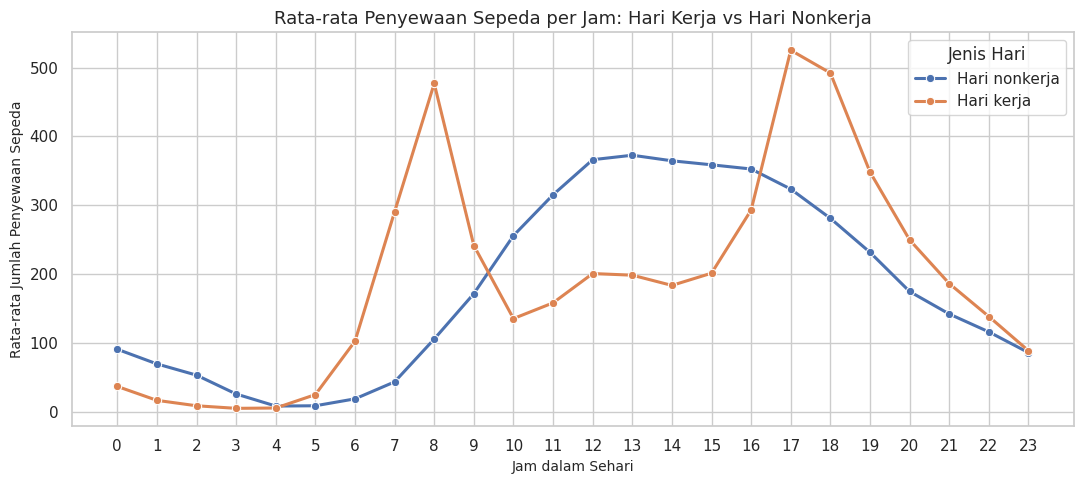

In [6]:
plt.figure(figsize=(11, 5))
sns.lineplot(
    data=hourly_pattern,
    x="hr",
    y="average_rentals",
    hue="day_type",
    marker="o",
    linewidth=2.2,
)
plt.title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Hari Nonkerja")
plt.xlabel("Jam dalam Sehari")
plt.ylabel("Rata-rata Jumlah Penyewaan Sepeda")
plt.xticks(range(0, 24))
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca?

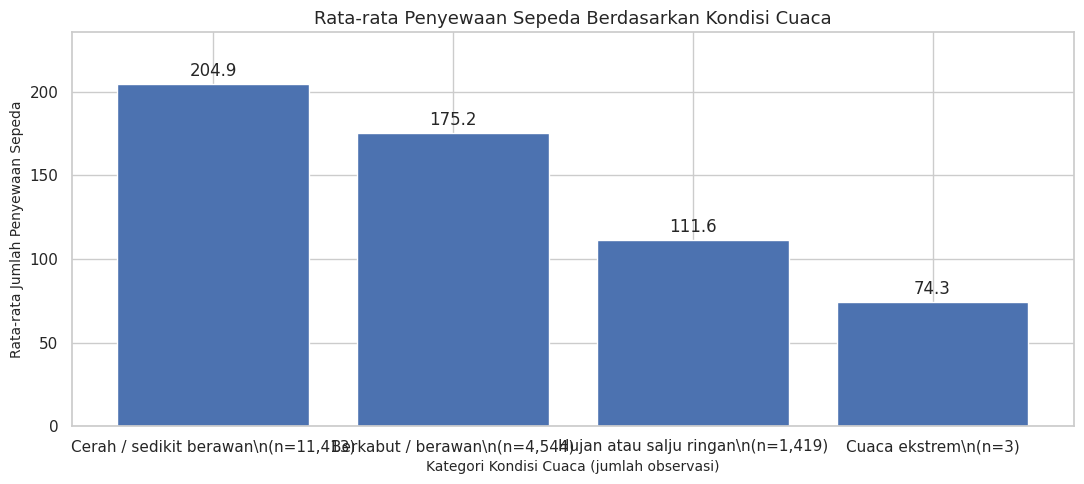

Catatan: kategori cuaca ekstrem hanya memiliki 3 observasi; nilai rata-ratanya tidak boleh digeneralisasi secara kuat.


In [7]:
weather_plot = weather_pattern.copy()
weather_plot["label_with_n"] = weather_plot.apply(
    lambda row: f"{row['weather_label']}\\n(n={int(row['observation_count']):,})",
    axis=1,
)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(
    weather_plot["label_with_n"],
    weather_plot["average_rentals"],
)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
ax.set_xlabel("Kategori Kondisi Cuaca (jumlah observasi)")
ax.set_ylabel("Rata-rata Jumlah Penyewaan Sepeda")
ax.tick_params(axis="x", labelrotation=0)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

print(
    "Catatan: kategori cuaca ekstrem hanya memiliki",
    int(weather_plot.loc[weather_plot["weathersit"] == 4, "observation_count"].iloc[0]),
    "observasi; nilai rata-ratanya tidak boleh digeneralisasi secara kuat."
)

**Insight:**
- Pada hari kerja, rata-rata penyewaan memperlihatkan puncak pada jam berangkat dan pulang kerja, terutama sekitar pukul 08.00 serta 17.00–18.00.
- Pada hari nonkerja, rata-rata penyewaan cenderung lebih tinggi pada siang hingga sore hari, dengan puncak sekitar pukul 13.00.
- Rata-rata penyewaan tertinggi terdapat pada kategori cuaca cerah atau sedikit berawan, kemudian menurun pada kategori yang menggambarkan kondisi cuaca lebih buruk.
- Kategori cuaca ekstrem hanya memiliki **3 observasi**, sehingga rata-ratanya tidak cukup kuat untuk dijadikan dasar tunggal dalam menetapkan kebijakan operasional.

## Analisis Lanjutan (Opsional)

Sebagai analisis tambahan yang relevan dengan kebutuhan operasional, jam dalam sehari dikelompokkan (*binning*) menjadi lima periode: dini hari, pagi, siang, sore, dan malam. Pengelompokan ini memudahkan perencanaan ketersediaan sepeda dan petugas berdasarkan periode waktu, tanpa menggunakan algoritma machine learning.

,day_type,time_period,average_rentals,total_rentals,observation_count
0,Hari kerja,Dini hari (00–05),16.435096,47859,2912
1,Hari kerja,Pagi (06–09),277.909274,551372,1984
2,Hari kerja,Siang (10–15),179.662085,535932,2983
3,Hari kerja,Sore (16–19),414.754764,827021,1994
4,Hari kerja,Malam (20–23),165.776104,330226,1992
5,Hari nonkerja,Dini hari (00–05),42.998534,58650,1364
6,Hari nonkerja,Pagi (06–09),85.000000,78370,922
7,Hari nonkerja,Siang (10–15),338.945887,469779,1386
8,Hari nonkerja,Sore (16–19),297.340564,274148,922
9,Hari nonkerja,Malam (20–23),129.697826,119322,920


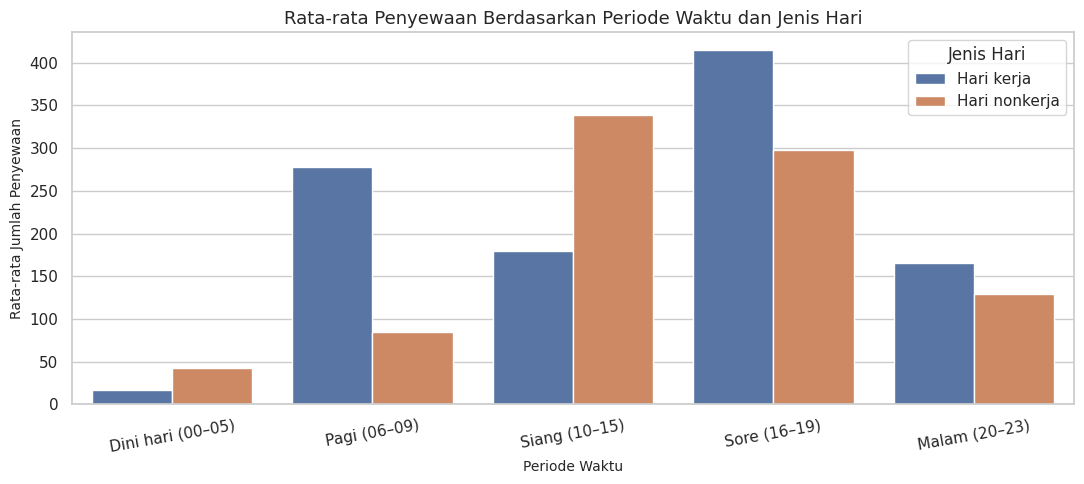

In [8]:
time_bins = [-1, 5, 9, 15, 19, 23]
time_labels = [
    "Dini hari (00–05)",
    "Pagi (06–09)",
    "Siang (10–15)",
    "Sore (16–19)",
    "Malam (20–23)",
]

clean_df["time_period"] = pd.cut(
    clean_df["hr"],
    bins=time_bins,
    labels=time_labels,
    include_lowest=True,
)

period_pattern = (
    clean_df.groupby(["day_type", "time_period"], observed=True, as_index=False)
    .agg(
        average_rentals=("cnt", "mean"),
        total_rentals=("cnt", "sum"),
        observation_count=("cnt", "size"),
    )
)

display(period_pattern)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=period_pattern,
    x="time_period",
    y="average_rentals",
    hue="day_type",
)
plt.title("Rata-rata Penyewaan Berdasarkan Periode Waktu dan Jenis Hari")
plt.xlabel("Periode Waktu")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(rotation=10)
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja, rata-rata penyewaan tertinggi terdapat pada periode sore (sekitar **414,8** sepeda per jam), diikuti periode pagi (sekitar **277,9**).
- Pada hari nonkerja, rata-rata penyewaan tertinggi terdapat pada periode siang (sekitar **338,9**), diikuti periode sore (sekitar **297,3**).
- Pengelompokan periode waktu memperjelas bahwa pola operasional hari kerja dan hari nonkerja tidak sama, sehingga jadwal kesiapan sepeda sebaiknya dibedakan menurut jenis hari.

## Conclusion & Recommendation

Kesimpulan berikut menjawab kedua pertanyaan bisnis berdasarkan hasil pengelompokan dan visualisasi. Rekomendasi disusun sebagai arahan operasional yang masih perlu disesuaikan dengan kondisi lapangan dan data terbaru apabila digunakan untuk keputusan aktual.

- **Conclusion pertanyaan 1:** Pola penyewaan per jam berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, rata-rata penyewaan tertinggi terjadi pada pukul **17.00** (sekitar 525 sepeda per jam), diikuti pukul **18.00** (sekitar 492) dan **08.00** (sekitar 477). Pada hari nonkerja, puncak terjadi pada pukul **13.00** (sekitar 373), diikuti pukul **12.00** (sekitar 366) dan **14.00** (sekitar 365). Dengan demikian, pola permintaan hari kerja lebih terkonsentrasi pada jam perjalanan kerja, sedangkan hari nonkerja lebih terkonsentrasi pada siang hari.
- **Conclusion pertanyaan 2:** Rata-rata penyewaan per jam tertinggi terjadi pada kondisi cuaca cerah atau sedikit berawan, yaitu sekitar **204,9** penyewaan. Pada kondisi berkabut atau berawan, rata-rata sekitar **175,2**, sedangkan pada hujan atau salju ringan sekitar **111,6**. Kategori cuaca ekstrem memiliki rata-rata sekitar **74,3**, tetapi hanya didasarkan pada **3 observasi** sehingga hasilnya belum cukup representatif untuk generalisasi. Perbedaan ini menunjukkan adanya hubungan pola antara kategori cuaca dan jumlah penyewaan pada dataset, bukan bukti sebab-akibat.

**Rekomendasi Action Item:**
- **Penjadwalan ketersediaan sepeda pada hari kerja:** prioritaskan pemeriksaan dan kesiapan sepeda sebelum jam 07.00–09.00 serta 16.00–19.00 untuk mengantisipasi puncak permintaan pagi dan sore.
- **Penyesuaian operasional pada hari nonkerja:** pertimbangkan peningkatan kesiapan sepeda dan petugas pada periode 12.00–16.00 karena rata-rata penyewaan relatif tinggi pada rentang tersebut.
- **Pemantauan kondisi cuaca:** gunakan informasi cuaca sebagai salah satu masukan perencanaan, tetapi jangan menetapkan kebijakan berdasarkan kategori cuaca ekstrem dari dataset ini saja karena hanya tersedia tiga observasi.
- **Evaluasi berkala:** perbarui analisis menggunakan data operasional terbaru sebelum menerapkan perubahan kapasitas, karena dataset yang dianalisis hanya mencakup tahun 2011–2012.

**Sumber data dan referensi:**

Bike Sharing Dataset, catatan penyewaan Capital Bikeshare, Washington D.C., tahun 2011–2012. Dokumentasi dataset mencantumkan publikasi terkait: Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. Progress in Artificial Intelligence. https://doi.org/10.1007/s13748-013-0040-3.

**Catatan identitas:** lengkapi alamat email Dicoding dan ID/username Dicoding pada bagian identitas sebelum notebook dikumpulkan.
